# Generate the test images

Generates the 12 images listed in `GENERATORS` below, 32-bit float in $[0, 1]$, and
saves them in this folder as `synthetic_<name>_<size>.tif`, or `composition_<name>_<size>.tif`
for the four `rings_degraded` images, which compose rings, a ramp and noise. The generators
are in `synthetic_images_2D.py`. The default size is $N = 512$ pixels; `SIZES` holds the
exceptions (`chirp` at $1024$, the four `rings_degraded` at $384$).

The real image `collagen.tif` is not generated: it is a real acquisition of collagen fibers
stored in this folder.

In [72]:
import os
from functools import partial
import numpy as np
import matplotlib.pyplot as plt
import synthetic_images_2D as sim
import importlib
importlib.reload(sim)
plt.rcParams.update({
    'figure.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 10,
    'axes.edgecolor': '#cfcec6', 'grid.color': '#e8e8e4', 'grid.linewidth': 0.8,
})

In [73]:
# degradation levels of rings_degraded (structure vs nematic assessment):
# ratio of saturated pixels, standard deviation of the Gaussian noise, slope of the ramp
DEGRADATION = {
    'none': dict(saturation=0.0, noise=0.0, ramp=0.0),
    'low': dict(saturation=0.4, noise=0.005, ramp=0.01),
    'medium': dict(saturation=0.6, noise=0.015, ramp=0.02),
    'high': dict(saturation=0.8, noise=0.025, ramp=0.05),
}

GENERATORS = {
    'chirp': sim.chirp,
    'wave': sim.wave,
    'spiral': sim.spiral,
    'rings_dither': sim.rings_dither,
    'noise': sim.noise,
    'filaments': sim.filaments,
    'nematic': sim.nematic,
    'bundles': sim.bundles,
    'rings_degraded_none': partial(sim.rings_degraded, **DEGRADATION['none']),
    'rings_degraded_low': partial(sim.rings_degraded, **DEGRADATION['low']),
    'rings_degraded_medium': partial(sim.rings_degraded, **DEGRADATION['medium']),
    'rings_degraded_high': partial(sim.rings_degraded, **DEGRADATION['high']),
}

# per-image size; every other image uses the default sim.N
SIZES = {'chirp': 1024, 'rings_degraded_none': 384, 'rings_degraded_low': 384,
         'rings_degraded_medium': 384, 'rings_degraded_high': 384}

# file prefix; every other image is saved as synthetic_<name>_<size>.tif
PREFIXES = {'rings_degraded_none': 'composition', 'rings_degraded_low': 'composition',
            'rings_degraded_medium': 'composition', 'rings_degraded_high': 'composition'}

images = {}
for name, generator in GENERATORS.items():
    images[name] = generator(SIZES.get(name, sim.N))

for name in images:
    path = sim.save(images[name], name, prefix=PREFIXES.get(name, 'synthetic'))
    print('saved', path, ' ', images[name].shape)

saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_chirp_1024.tif   (1024, 1024)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_wave_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_spiral_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_rings_dither_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_noise_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_filaments_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_nematic_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/synthetic_bundles_512.tif   (512, 512)
saved /Users/dsage/Desktop/dev/OrientationJ/test-images/code/../images/composition_rings_degraded_none_384.tif   (384,

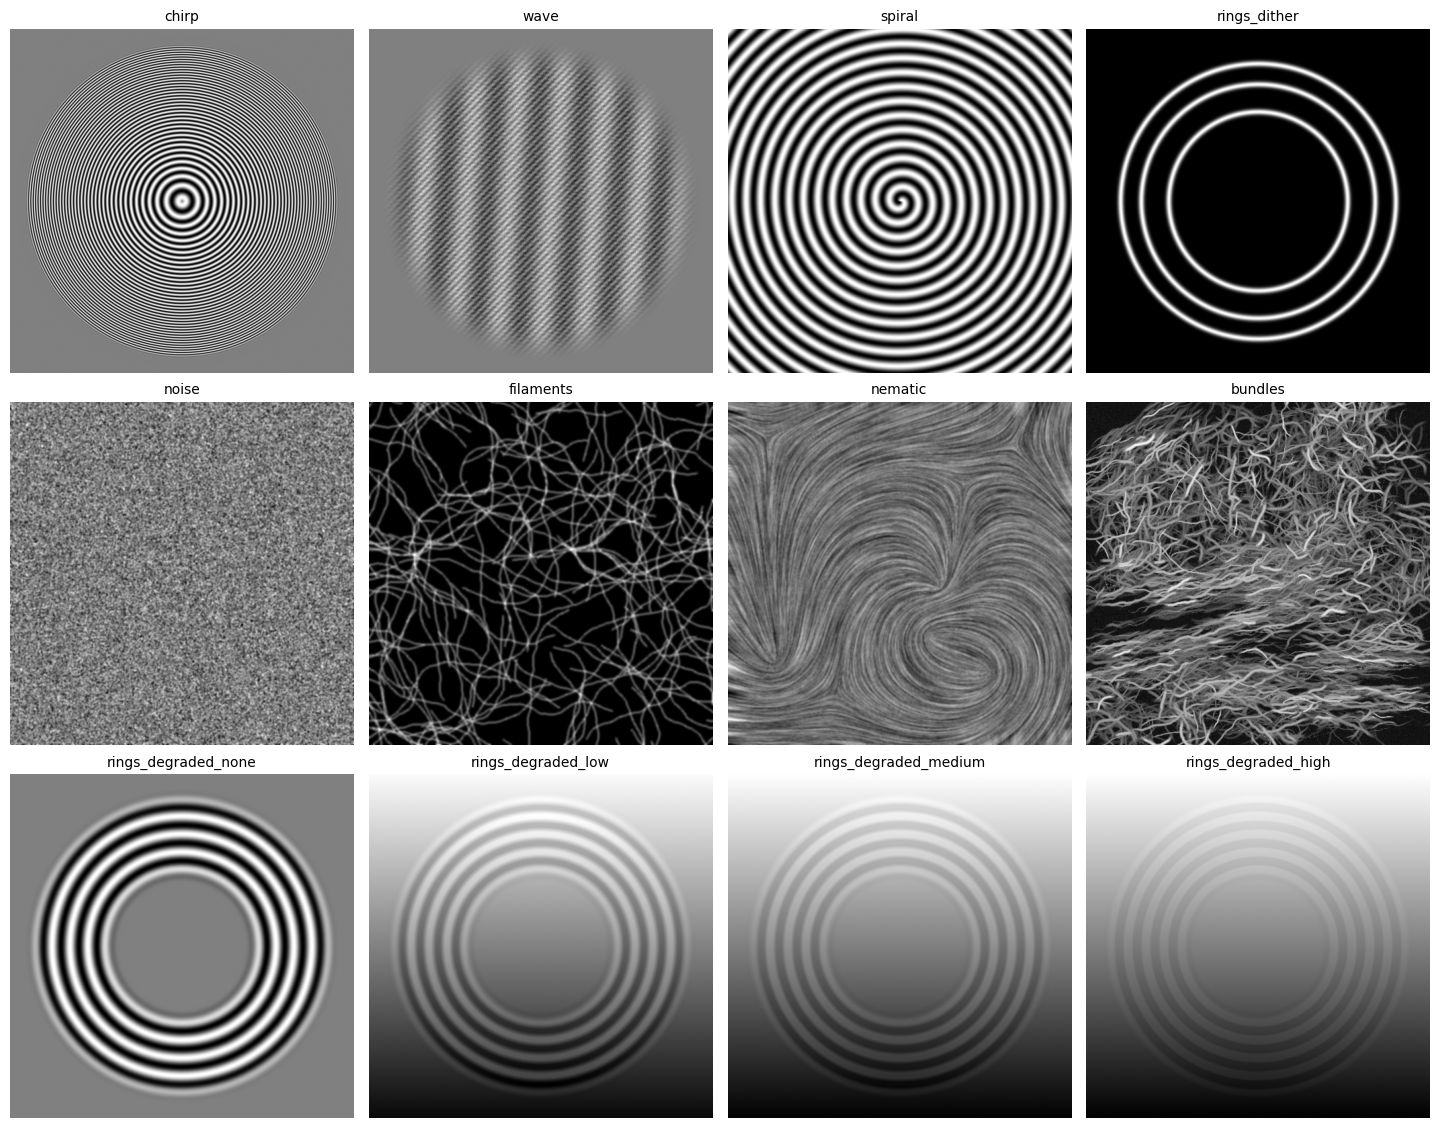

In [3]:
names = list(images.keys())
rows = (len(names) + 3) // 4
fig, axes = plt.subplots(rows, 4, figsize=(14.5, 3.8 * rows))
for ax in axes.ravel():
    ax.axis('off')
for index in range(len(names)):
    ax = axes[index // 4][index % 4]
    ax.imshow(images[names[index]], cmap='gray')
    ax.set_title(names[index])
fig.tight_layout()
plt.show()

All images are square, 32-bit float in $[0, 1]$: $512 × 512$ except `chirp` at
$1024 × 1024$ and the four `rings_degraded` at $384 × 384$. `wave` is the superposition of three waves of equal amplitude with fringes at exactly
$5°$, $45°$ and $85°$ and periods of 2 (the Nyquist limit), 8 and 64 pixels, plus uniform
noise of amplitude 0.5, multiplied by a circular Tukey window of 480 px diameter;
`rings_dither` is a few full rings around the center with a Gaussian radial profile, plus an
invisible dither ($σ = 10^{-4}$) that breaks the exact central symmetry of the pattern —
without it, the orientation distribution shows artificial spikes at exactly $0$, $±45$ and
$±90$ degrees. `bundles` is a matted web of 4000 wavy fibers, each a persistent random walk
like `filaments` but rendered as a lit tube of radius 0.1–3 px, lognormal length (median 45 px)
and tapered ends; every fiber starts on an existing fiber when one is found, which knits the
web with junctions. Three elliptical patches of random position, size and direction pull the
heading of the walk toward their direction: the bundles.

`rings_degraded` is the test image of the
[structure vs nematic](https://Biomedical-Imaging-Group.github.io/OrientationJ/assessment/structure-nematic/)
assessment: sine rings of period 20 px on an annulus of radii 70–175 px with smooth edges, on a
vertical ramp, plus Gaussian noise. The generator takes the three degradations as parameters;
the four levels, which set together the ratio of saturated (clipped) pixels, the noise and the
slope of the ramp, are defined in this notebook (`DEGRADATION`):

| level | saturated pixels $ρ$ | noise $σ$ | ramp slope $β$ |
|---|---|---|---|
| none | 0 | 0 | 0 |
| low | 0.4 | 0.005 | 0.01 |
| medium | 0.6 | 0.015 | 0.02 |
| high | 0.8 | 0.025 | 0.05 |

The reference orientation is tangential; the evaluation mask (`rings_mask`) is the annulus where
the window is full.